# MÔ HÌNH AI ĐỊNH GIÁ CĂN HỘ CHUNG CƯ – THỦ DẦU MỘT VÀ VÙNG LÂN CẬN

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01
**Môn:** Học máy

Notebook `2324801030095.ipynb` định giá **nhà gắn liền với đất** (nhà phố, nhà hẻm, biệt thự). Notebook này định giá **căn hộ chung cư**. Đây là một dạng nhà ở phổ biến; ngay tại Phú Hòa có các dự án như Happy One Central.

**Vì sao tách thành mô hình riêng?** Căn hộ được định giá theo cơ chế khác nhà phố:

| | Nhà phố | Căn hộ chung cư |
|---|---|---|
| Đơn vị giá | triệu / m² **đất** | triệu / m² **sử dụng** (thông thủy) |
| Yếu tố quyết định | diện tích đất, mặt tiền / hẻm, vị trí | **dự án** (chủ đầu tư, tiện ích, tuổi tòa nhà), vị trí |
| Yếu tố riêng | số tầng nhà, độ rộng hẻm | **tầng của căn**, view, pháp lý (sổ hồng hay hợp đồng mua bán), đã bàn giao chưa, nhà ở xã hội |

Gộp chung một mô hình sẽ làm sai cả hai loại, nên ta dùng cùng **quy trình** (thu thập → làm sạch → kiểm định chéo lặp chia theo nhóm → chọn mô hình → khoảng tin cậy → chẩn đoán) nhưng **đặc trưng và mô hình riêng**.

**Dữ liệu:** tin rao bán căn hộ thật trên Chợ Tốt Nhà (toàn Bình Dương cũ) và alonhadat (Thủ Dầu Một). Không có dữ liệu mô phỏng.

> Chạy lần lượt các ô từ trên xuống (Restart & Run All, vài phút).

**Phạm vi kiến thức** (notebook này là **phần mở rộng** của đề tài; notebook chính `2324801030095.ipynb` mới là bài làm theo môn học). Bước 6b là **Phần A**: chỉ dùng các mô hình của môn học; từ Bước 7 là **Phần B** (nâng cao):

| Trong môn học (bài giảng / thực hành) | Ngoài môn học (nâng cao) |
|---|---|
| Tiền xử lý: thiếu, trùng, ngoại lai (TH4); trích đặc trưng từ mô tả (TH6); chia train/test; **Phần A:** hồi quy tuyến tính, cây quyết định, KNN, SVR, MLP, Random Forest; dò siêu tham số bằng GridSearchCV; hồi quy tuyến tính có phạt (Ridge); kiểm định chéo K-fold; MAE, MAPE, R² | LightGBM với hàm mất mát Huber; stacking với mô hình chữ TF-IDF; đơn giá dự án/phường phân tầng (target encoding có co); chia fold theo nhóm tin gần trùng; khoảng tin cậy bootstrap; khoảng giá 80% từ sai số ngoài-fold |

## Bước 1: Thu thập dữ liệu

| Nguồn | Script | Phạm vi | Thông tin |
|---|---|---|---|
| Chợ Tốt Nhà | `python src/thu_thap.py chotot --can-ho` | Danh mục "Căn hộ/Chung cư", toàn Bình Dương cũ | Giá, diện tích sử dụng, phòng ngủ, WC, **tên dự án**, loại căn hộ (chung cư, nhà ở xã hội, duplex, penthouse…), tầng, pháp lý, bàn giao, nội thất, tọa độ |
| alonhadat | `python src/thu_thap.py alonhadat --can-ho` | Căn hộ chung cư, TP. Thủ Dầu Một | Giá, diện tích, phòng ngủ, địa chỉ, mô tả |

Thị trường căn hộ Bình Dương cũ tập trung ở Dĩ An và Thuận An (giáp TP.HCM). Thủ Dầu Một có ít dự án hơn. Mô hình học trên toàn vùng, vì giá căn hộ phụ thuộc chủ yếu vào dự án và vị trí, và những yếu tố này đã có trong đặc trưng.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
nx = lambda s: display(Markdown(s))                                             # in nhận xét có số liệu tính từ kết quả
vn = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")   # 1234.5 -> 1.234,5

import sys
# Thư mục gốc của đề tài: notebook nằm trong notebooks/, mã dùng chung ở src/, dữ liệu ở dataset/
GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(GOC / "src"))
RAW, PROC, LICH_SU = GOC / "dataset" / "raw", GOC / "dataset" / "processed", GOC / "dataset" / "history"
MODEL_DIR, KET_QUA = GOC / "models", GOC / "results"
MODEL_DIR.mkdir(exist_ok=True); KET_QUA.mkdir(exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
from mo_hinh_gia import (khong_dau, ten_phuong, ten_quan, ten_du_an, trich_dac_trung_chu, nhom_gan_trung, hieu_chinh_khoang, phan_vi_cho,
                         MoHinhGia, XepChongChu, BaselineDonGiaDuAn, mo_hinh_co_ban,
                         du_doan_cheo_lap, sai_so_tung_can, ktc_bootstrap, bang_danh_gia)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

raw_ct = pd.read_csv(RAW / "chotot_can_ho_raw.csv")
raw_al = pd.read_csv(RAW / "alonhadat_can_ho_tdm_raw.csv")
print(f"Chợ Tốt: {len(raw_ct)} tin ({(raw_ct['loai_tin'] == 'ban').sum()} tin bán, {(raw_ct['loai_tin'] != 'ban').sum()} tin cho thuê – bỏ), "
      f"thu thập {raw_ct['ngay_thu_thap'].iloc[0]}")
print(f"alonhadat: {len(raw_al)} tin, thu thập {raw_al['ngay_thu_thap'].iloc[0]}")
raw_ct[raw_ct["loai_tin"] == "ban"].groupby("quan_huyen").size().sort_values(ascending=False).to_frame("Số tin bán")

Chợ Tốt: 2039 tin (845 tin bán, 1194 tin cho thuê – bỏ), thu thập 2026-11-26
alonhadat: 20 tin, thu thập 2026-11-26


,Số tin bán
quan_huyen,
Thành phố Thuận An,324
Thành phố Dĩ An,300
Thành phố Thủ Dầu Một,181
Thị xã Bến Cát,38
Thị xã Tân Uyên,2


## Bước 2: Hợp nhất 2 nguồn
Đưa về một bảng chung. Để dùng lại các lớp mô hình của notebook nhà phố, cột `dt_dat` ở đây chứa **diện tích sử dụng** của căn hộ, còn cột `duong` chứa **tên dự án**. Nhờ vậy đặc trưng "giá khu vực" tự trở thành **đơn giá trung bình của dự án** và của các căn gần nhất.

In [2]:
c = raw_ct[raw_ct["loai_tin"] == "ban"]
NOI_THAT = {"Nội thất cao cấp": 3, "Nội thất đầy đủ": 2, "Hoàn thiện cơ bản": 1, "Bàn giao thô": 0, "Nhà trống": 0}
C = pd.DataFrame({
    "nguon": "chotot", "id": c["id"].astype(str), "url": c["url"], "ngay_dang": c["ngay_dang"], "tieu_de": c["tieu_de"],
    "mo_ta": c["mo_ta"].fillna(""), "gia_ty": c["gia"] / 1e9, "dt_dat": c["dt_su_dung"], "phong_ngu": c["phong_ngu"], "so_wc": c["so_wc"],
    "tang_so": pd.to_numeric(c["tang_so"], errors="coerce"), "quan": c["quan_huyen"].map(ten_quan), "phuong": c["phuong"].map(ten_phuong),
    "du_an": c["du_an"].map(ten_du_an), "du_an_goc": c["du_an"], "lat": c["lat"], "lon": c["lon"],
    "loai_can_ho": c["loai_can_ho"],
    "noxh": (c["loai_can_ho"] == "Nhà ở xã hội").astype(float),
    "loai_dac_biet": c["loai_can_ho"].isin(["Duplex", "Penthouse"]).astype(float),
    "can_ho_dich_vu": (c["loai_can_ho"] == "Căn hộ dịch vụ").astype(float),
    "da_ban_giao": c["tinh_trang_ban_giao"].map({"Đã bàn giao": 1.0, "Chưa bàn giao": 0.0}),
    "so_hong": c["phap_ly"].map({"Sổ hồng riêng": 1.0, "Hợp đồng mua bán": 0.0, "Đang chờ sổ": 0.0, "Hợp đồng đặt cọc": 0.0}),
    "noi_that_cap": c["noi_that"].map(NOI_THAT),
})
a = raw_al
dc = a["dia_chi_cu"].fillna("").str.split(",")
A = pd.DataFrame({
    "nguon": "alonhadat", "id": a["id"].astype(str), "url": a["url"], "ngay_dang": a["ngay_dang"], "tieu_de": a["tieu_de"],
    "mo_ta": a["mo_ta"].fillna(""), "gia_ty": pd.to_numeric(a["gia"]) / 1e9,
    "dt_dat": pd.to_numeric(a["dt_dat"].astype(str).str.replace(",", "."), errors="coerce"),
    "phong_ngu": a["phong_ngu"], "so_wc": np.nan, "tang_so": np.nan, "quan": "thu dau mot",
    "phuong": dc.map(lambda p: ten_phuong(p[1]) if len(p) > 2 else None), "du_an": None, "du_an_goc": None,
    "lat": np.nan, "lon": np.nan, "loai_can_ho": None, "noxh": np.nan, "loai_dac_biet": np.nan, "can_ho_dich_vu": np.nan,
    "da_ban_giao": np.nan, "so_hong": np.nan, "noi_that_cap": np.nan,
})
df = pd.concat([C, A], ignore_index=True)
ngoai_vung = df["lat"].notna() & ~(df["lat"].between(10.82, 11.65) & df["lon"].between(106.30, 106.95))
df.loc[ngoai_vung, ["lat", "lon"]] = np.nan
df["van_ban"] = (df["tieu_de"].fillna("") + " . " + df["mo_ta"].fillna("")).map(khong_dau)

# Tin chưa ghi dự án: tìm tên dự án đã biết trong tiêu đề / mô tả (tên dài trước để không khớp nhầm tên ngắn)
ds_du_an = sorted({d for d in df["du_an"].dropna() if len(d) >= 5}, key=lambda d: (-len(d), d))
df["du_an"] = df["du_an"].fillna(df["van_ban"].map(lambda t: next((d for d in ds_du_an if d in t), None)))
print("Bảng hợp nhất:", df.shape, "| tỷ lệ tin xác định được dự án:", round(df["du_an"].notna().mean() * 100), "%")
df.groupby("nguon")[["dt_dat", "phong_ngu", "so_wc", "tang_so", "du_an", "so_hong", "da_ban_giao", "noi_that_cap", "lat"]] \
  .agg(lambda s: s.notna().mean() * 100).round(0).T.rename_axis("% có dữ liệu")

Bảng hợp nhất: (865, 25) | tỷ lệ tin xác định được dự án: 82 %


nguon,alonhadat,chotot
% có dữ liệu,,
dt_dat,100.0,98.0
phong_ngu,100.0,98.0
so_wc,0.0,80.0
tang_so,0.0,32.0
du_an,30.0,83.0
so_hong,0.0,78.0
da_ban_giao,0.0,72.0
noi_that_cap,0.0,78.0
lat,0.0,100.0


## Bước 3: Trích đặc trưng từ mô tả
Dùng lại 21 từ khóa của notebook nhà phố, thêm 4 từ khóa riêng của căn hộ:
- **t_view:** view sông / hồ / công viên / thành phố;
- **t_tang_cao:** nhấn mạnh "tầng cao";
- **t_so_cap:** dấu hiệu bán từ **chủ đầu tư** (thanh toán theo tiến độ, trả trước, chiết khấu, mở bán…), tức giá sơ cấp;
- **t_noxh:** nhà ở xã hội.

Ngoài ra đọc **số tầng của căn** ("tầng 12") và số phòng ngủ / WC khi ô thông số trống.

In [3]:
T = trich_dac_trung_chu(df["van_ban"])
v = df["van_ban"]
T["t_view"] = v.str.contains(r"view (?:song|ho|cong vien|thanh pho|landmark|ho boi)|huong song|nhin ra song").astype(int)
T["t_tang_cao"] = v.str.contains(r"tang cao|view cao").astype(int)
T["t_so_cap"] = v.str.contains(r"chu dau tu|\bcdt\b|thanh toan \d|tra truoc|chiet khau|ho tro vay|gia goc|mo ban|booking|ban giao nam|uu dai").astype(int)
T["t_noxh"] = v.str.contains(r"nha o xa hoi|\bnoxh\b").astype(int)
df = pd.concat([df, T], axis=1)
df["phong_ngu"] = df["phong_ngu"].where(df["phong_ngu"].between(0, 6)).fillna(df["t_pn"])
df["so_wc"] = df["so_wc"].where(df["so_wc"].between(1, 6)).fillna(df["t_wc"])
tang = pd.to_numeric(v.str.extract(r"\btang (\d{1,2})\b", expand=False), errors="coerce")
df["tang_so"] = df["tang_so"].where(df["tang_so"].between(1, 60)).fillna(tang.where(tang.between(1, 60)))
df["noxh"] = df["noxh"].fillna(df["t_noxh"])
df["noi_that_cap"] = df["noi_that_cap"].fillna(pd.Series(np.where(df["t_noi_that"] == 1, 2.0, np.nan), index=df.index))
CO_CHU = [c_ for c_ in T.columns if T[c_].dtype.kind == "i"]
(df[["t_view", "t_tang_cao", "t_so_cap", "t_noxh", "t_noi_that", "t_ban_gap", "t_goc"]].mean() * 100).round(1).to_frame("% số tin").T

,t_view,t_tang_cao,t_so_cap,t_noxh,t_noi_that,t_ban_gap,t_goc
% số tin,7.6,3.5,38.3,5.0,43.6,27.7,8.9


## Bước 4: Làm sạch

1. **Phạm vi:** giá 0,3–15 tỷ, diện tích sử dụng 20–250 m², đơn giá 8–150 triệu/m².
2. **Tin trùng khớp hẳn** (cùng quận, cùng giá, cùng diện tích): giữ 1 dòng, gộp thông tin.
3. **Giá "chỉ từ"**: tin bán của chủ đầu tư thường ghi "giá chỉ từ … tỷ". Đó là giá **thấp nhất của cả dự án**, không phải giá của căn đang rao, nên loại. Giá mồi kiểu "2 tỷ xxx" và tin đăng **"bảng giá"** của cả dự án (không phải một căn cụ thể) cũng bị loại.
4. **Đơn giá lệch hơn 2,5 lần** so với 10 căn hộ gần nhất: gần như chắc chắn là lỗi nhập.
5. **Tọa độ:** tin thiếu tọa độ lấy tọa độ trung vị của dự án, nếu không có thì lấy tâm phường.
6. **Nhóm tin gần trùng** (cùng căn đăng lại) dùng cho đánh giá. Khác nhà phố, với căn hộ chỉ gom khi **nội dung tin giống nhau**. Một dự án có rất nhiều căn cùng mẫu (cùng diện tích, giá gần nhau) nhưng là các căn khác nhau. Nếu gom theo "cùng dự án + cùng diện tích", cả dự án bị giấu khỏi tập học khi kiểm tra, và mô hình bị đánh giá sai (đoán cao giá nhà ở xã hội có nhiều căn giống hệt nhau).

**Nhà ở xã hội được GIỮ LẠI** (khác notebook nhà phố). Ở Bình Dương, căn hộ nhà ở xã hội (các dự án Becamex) là một phân khúc lớn và được mua bán lại trên thị trường. Mô hình nhận biết phân khúc này qua cột `noxh`.

In [4]:
from sklearn.neighbors import BallTree

n0 = len(df)
df = df[df["gia_ty"].between(0.3, 15) & df["dt_dat"].between(20, 250)].copy()
df["don_gia"] = df["gia_ty"] * 1000 / df["dt_dat"]
df = df[df["don_gia"].between(8, 150)].copy()
n1 = len(df)
df = df.sort_values("nguon", key=lambda s: s.map({"chotot": 0, "alonhadat": 1}), kind="stable")
df["k_trung"] = df.groupby(["quan", (df["gia_ty"] * 100).round(), df["dt_dat"].round()]).ngroup()
df = df.groupby("k_trung", as_index=False).first()
n2 = len(df)

xy_da = df.dropna(subset=["lat"]).groupby(["quan", "du_an"])[["lat", "lon"]].median()
xy_ph = df.dropna(subset=["lat"]).groupby(["quan", "phuong"])[["lat", "lon"]].median()
muc = []
for i, r in df.iterrows():
    if pd.notna(r["lat"]):
        muc.append("tọa độ của tin")
    elif (r["quan"], r["du_an"]) in xy_da.index:
        df.loc[i, ["lat", "lon"]] = xy_da.loc[(r["quan"], r["du_an"])].values; muc.append("theo dự án")
    elif (r["quan"], r["phuong"]) in xy_ph.index:
        df.loc[i, ["lat", "lon"]] = xy_ph.loc[(r["quan"], r["phuong"])].values; muc.append("tâm phường")
    else:
        muc.append("không có")
df["muc_toa_do"] = muc
df = df[df["lat"].notna()].reset_index(drop=True)

ly_do = pd.Series("", index=df.index)
moi = df["van_ban"].str.contains(r"(?:gia|chi)\s*(?:chi\s*)?tu\s*\d|\d\s*(?:ty|t)\s*x{2,}")
ly_do[moi] = "Giá 'chỉ từ' / giá mồi"
ly_do[(ly_do == "") & df["tieu_de"].fillna("").map(khong_dau).str.contains(r"bang gia")] = "Bảng giá cả dự án, không phải một căn"
xy = np.radians(df[["lat", "lon"]].to_numpy()); u = np.log(df["don_gia"].to_numpy())
_, idx = BallTree(xy, metric="haversine").query(xy, k=11)
lech = np.abs(u - np.median(u[idx[:, 1:]], axis=1)) > np.log(2.5)
ly_do[(ly_do == "") & lech] = "Đơn giá lệch > 2,5 lần khu vực"
df[ly_do != ""].assign(ly_do_loai=ly_do[ly_do != ""])[["nguon", "url", "tieu_de", "gia_ty", "dt_dat", "don_gia", "ly_do_loai"]] \
  .to_csv(PROC / "can_ho_bi_loai.csv", index=False, encoding="utf-8-sig")
print(f"Ngoài phạm vi: {n0 - n1} | trùng khớp: {n1 - n2} | bị loại theo quy tắc: {(ly_do != '').sum()} {ly_do[ly_do != ''].value_counts().to_dict()}")
df = df[ly_do == ""].reset_index(drop=True)

df["duong"] = df["du_an"]           # để GiaLangGieng tính đơn giá trung bình theo DỰ ÁN (cột lg_duong)
df["y"] = np.log(df["gia_ty"]); df["log_dt"] = np.log(df["dt_dat"])
df["phu_hoa"] = (df["phuong"] == "phu hoa").astype(int); df["tdm"] = (df["quan"] == "thu dau mot").astype(int)
df["kc_trung_tam_km"] = np.hypot((df["lat"] - 10.9805) * 110.6, (df["lon"] - 106.6520) * 109.3)
df["ngang"] = np.nan; df["dai"] = np.nan       # cột cần cho hàm gom nhóm gần trùng
df["nhom"] = nhom_gan_trung(df, dung_vi_tri=False)   # căn hộ: chỉ gom khi nội dung tin giống nhau (xem giải thích ở Bước 4)
print(f"Còn {len(df)} căn hộ | Thủ Dầu Một: {df['tdm'].sum()} | Phú Hòa: {df['phu_hoa'].sum()} | "
      f"{df['du_an'].nunique()} dự án | {df['nhom'].nunique()} nhóm tin gần trùng")

Ngoài phạm vi: 40 | trùng khớp: 183 | bị loại theo quy tắc: 60 {"Giá 'chỉ từ' / giá mồi": 54, 'Đơn giá lệch > 2,5 lần khu vực': 6}


Còn 580 căn hộ | Thủ Dầu Một: 116 | Phú Hòa: 18 | 79 dự án | 510 nhóm tin gần trùng


## Bước 5: Khám phá dữ liệu

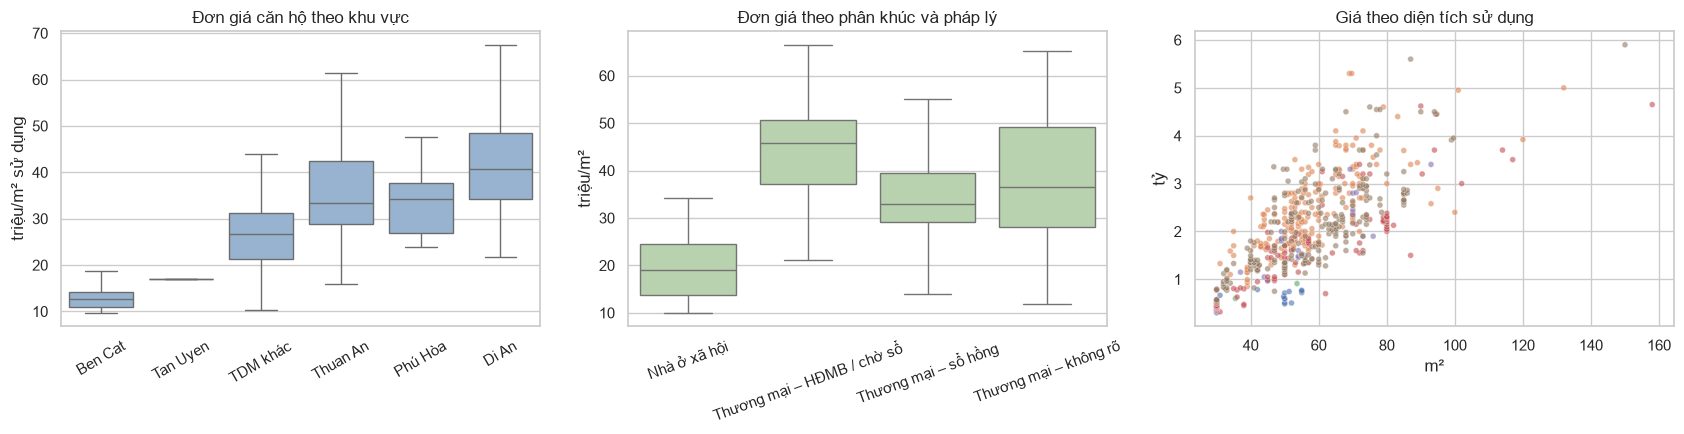

Các dự án có từ 8 tin trở lên:


,so_tin,quan,don_gia_tv,gia_tv
du_an,,,,
green skyline,22,di an,54.4,3.3
bcons newsky,16,thuan an,51.2,3.0
bcons city,21,di an,48.7,2.4
the rivana,17,thuan an,42.3,2.9
ht pearl,11,di an,42.1,3.2
the east gate,10,di an,38.8,2.0
happy one central,10,thu dau mot,37.4,2.4
bcons solary,8,di an,36.1,1.8
bcons garden,10,di an,33.2,1.8


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
nhom_kv = np.where(df["phu_hoa"] == 1, "Phú Hòa", np.where(df["tdm"] == 1, "TDM khác", df["quan"].str.title()))
thu_tu = pd.Series(df["don_gia"].values, index=nhom_kv).groupby(level=0).median().sort_values().index
sns.boxplot(x=nhom_kv, y=df["don_gia"], order=thu_tu, ax=axes[0], showfliers=False, color="#8fb3d9")
axes[0].set(title="Đơn giá căn hộ theo khu vực", ylabel="triệu/m² sử dụng", xlabel=""); axes[0].tick_params(axis="x", rotation=30)
loai = np.where(df["noxh"] == 1, "Nhà ở xã hội", np.where(df["so_hong"] == 1, "Thương mại – sổ hồng",
                np.where(df["so_hong"] == 0, "Thương mại – HĐMB / chờ sổ", "Thương mại – không rõ")))
sns.boxplot(x=loai, y=df["don_gia"], ax=axes[1], showfliers=False, color="#b6d7a8")
axes[1].set(title="Đơn giá theo phân khúc và pháp lý", ylabel="triệu/m²", xlabel=""); axes[1].tick_params(axis="x", rotation=20)
sns.scatterplot(x=df["dt_dat"], y=df["gia_ty"], hue=nhom_kv, alpha=0.6, s=18, ax=axes[2], legend=False)
axes[2].set(title="Giá theo diện tích sử dụng", xlabel="m²", ylabel="tỷ")
plt.tight_layout(); plt.show()

top = (df.groupby("du_an").agg(so_tin=("y", "size"), quan=("quan", "first"), don_gia_tv=("don_gia", "median"), gia_tv=("gia_ty", "median"))
         .query("so_tin >= 8").sort_values("don_gia_tv", ascending=False))
print("Các dự án có từ 8 tin trở lên:"); display(top.round(1))

**Pháp lý có làm giá cao hơn không?** So hai cách: (1) tổng thể; (2) **trong cùng một dự án** (chỉ các dự án có cả căn sổ hồng lẫn căn HĐMB), để loại ảnh hưởng của việc mỗi dự án có mặt bằng giá khác nhau.

In [6]:
tm = df[df["noxh"] == 0]
tong_ph = tm.groupby(tm["so_hong"].map({1.0: "Sổ hồng", 0.0: "HĐMB / chờ sổ"}))["don_gia"].median()
print("Tổng thể – đơn giá trung vị (tr/m²):", tong_ph.round(1).to_dict())
cap = []
for ten, g in tm.dropna(subset=["so_hong", "du_an"]).groupby("du_an"):
    if g["so_hong"].nunique() == 2:
        cap.append(np.log(g[g["so_hong"] == 1]["don_gia"]).median() - np.log(g[g["so_hong"] == 0]["don_gia"]).median())
cap = np.array(cap)
print(f"Trong cùng dự án ({len(cap)} dự án có cả hai loại): căn sổ hồng chênh {(np.exp(np.median(cap)) - 1) * 100:+.1f}% so với căn HĐMB (trung vị); "
      f"{(cap > 0).sum()} dự án sổ hồng cao hơn, {(cap < 0).sum()} dự án thấp hơn")
da_tv = tm.groupby("du_an")["don_gia"].median()
dg_xh = df.groupby("noxh")["don_gia"].median()
cung_da = tm.dropna(subset=["du_an"]).groupby("du_an").filter(lambda g: len(g) >= 5)
lx = np.log(cung_da["dt_dat"]) - cung_da.groupby("du_an")["dt_dat"].transform(lambda s: np.log(s).mean())
ly = np.log(cung_da["gia_ty"]) - cung_da.groupby("du_an")["gia_ty"].transform(lambda s: np.log(s).mean())
co_gian = np.polyfit(lx, ly, 1)[0]          # % giá tăng khi diện tích tăng 1%, trong cùng dự án
hd_cao = tong_ph["HĐMB / chờ sổ"] > tong_ph["Sổ hồng"]
cap_nho = abs(np.exp(np.median(cap)) - 1) < 0.05 and min((cap > 0).sum(), (cap < 0).sum()) >= len(cap) / 4
nx(f'''**Quan sát:**
- Đơn giá căn hộ chênh mạnh **giữa các dự án**: dự án đắt (10% trên cùng) có đơn giá trung vị gấp {vn(da_tv.quantile(0.9) / da_tv.quantile(0.1))} lần dự án rẻ (10% dưới cùng). Vì vậy tên dự án là thông tin quan trọng nhất.
- **Nhà ở xã hội** có đơn giá trung vị {vn(dg_xh.get(1, np.nan))} triệu/m² so với {vn(dg_xh.get(0, np.nan))} triệu/m² ở căn hộ thương mại.
- **Pháp lý:** nhìn tổng thể, căn chỉ có hợp đồng mua bán có đơn giá {"**cao hơn**" if hd_cao else "thấp hơn"} căn sổ hồng ({vn(tong_ph["HĐMB / chờ sổ"])} so với {vn(tong_ph["Sổ hồng"])} triệu/m²){", vì đó chủ yếu là căn của **dự án mới** chưa ra sổ" if hd_cao else ""}. So trong cùng một dự án thì {"chênh lệch nhỏ và không nhất quán" if cap_nho else "chênh lệch đáng kể"} (số liệu ở ô trên). {"Pháp lý ảnh hưởng chủ yếu tới **rủi ro, khả năng vay và thủ tục sang tên**, ít ảnh hưởng tới giá rao. " if cap_nho else ""}Đây là ví dụ cho thấy phải so sánh trong cùng điều kiện mới kết luận được.
- Trong cùng một dự án (các dự án ≥ 5 tin), diện tích tăng 1% thì giá tăng khoảng {vn(co_gian, 2)}% {"– giá gần như **tỷ lệ thuận với diện tích**" if abs(co_gian - 1) < 0.15 else ""}.''')

Tổng thể – đơn giá trung vị (tr/m²): {'HĐMB / chờ sổ': 45.8, 'Sổ hồng': 32.8}
Trong cùng dự án (15 dự án có cả hai loại): căn sổ hồng chênh +0.2% so với căn HĐMB (trung vị); 8 dự án sổ hồng cao hơn, 7 dự án thấp hơn


**Quan sát:**
- Đơn giá căn hộ chênh mạnh **giữa các dự án**: dự án đắt (10% trên cùng) có đơn giá trung vị gấp 2,1 lần dự án rẻ (10% dưới cùng). Vì vậy tên dự án là thông tin quan trọng nhất.
- **Nhà ở xã hội** có đơn giá trung vị 19,0 triệu/m² so với 35,3 triệu/m² ở căn hộ thương mại.
- **Pháp lý:** nhìn tổng thể, căn chỉ có hợp đồng mua bán có đơn giá **cao hơn** căn sổ hồng (45,8 so với 32,8 triệu/m²), vì đó chủ yếu là căn của **dự án mới** chưa ra sổ. So trong cùng một dự án thì chênh lệch nhỏ và không nhất quán (số liệu ở ô trên). Pháp lý ảnh hưởng chủ yếu tới **rủi ro, khả năng vay và thủ tục sang tên**, ít ảnh hưởng tới giá rao. Đây là ví dụ cho thấy phải so sánh trong cùng điều kiện mới kết luận được.
- Trong cùng một dự án (các dự án ≥ 5 tin), diện tích tăng 1% thì giá tăng khoảng 0,92% – giá gần như **tỷ lệ thuận với diện tích**.

## Bước 6: Cách đánh giá
Giống notebook nhà phố: **tập test** gồm 20% số nhóm tin gần trùng, giữ riêng để kiểm tra lần cuối; **kiểm định chéo 5-fold lặp 3 lần chia theo nhóm** trên tập train để so sánh và chọn mô hình; mọi chỉ số kèm **khoảng tin cậy 95%** (bootstrap theo nhóm).

Chia theo nhóm bảo đảm một căn được đăng nhiều lần (cùng nội dung) không vừa được học vừa được dùng để chấm. Các căn **khác nhau** trong cùng dự án vẫn có thể nằm ở tập học, đúng như khi dùng thật: muốn định giá một căn thì ta đã biết giá các căn khác của dự án đó.

In [7]:
from sklearn.model_selection import GroupShuffleSplit
_, vt_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE).split(df, groups=df["nhom"]))
df["tap"] = np.where(df.index.isin(vt_test), "test", "train")
train, test = df[df["tap"] == "train"].reset_index(drop=True), df[df["tap"] == "test"].reset_index(drop=True)
assert not set(train["nhom"]) & set(test["nhom"])
pd.crosstab(df["tap"], np.where(df["tdm"] == 1, "Thủ Dầu Một", "Huyện/TP khác"))

col_0,Huyện/TP khác,Thủ Dầu Một
tap,,
test,91,19
train,373,97


## Bước 6b: Phần A – các mô hình cơ bản của môn học
Trước khi dùng kỹ thuật nâng cao, thử đúng các mô hình học có giám sát trong bài giảng / thực hành, giống Phần A của notebook chính:

| Mô hình | Nguồn trong môn học |
|---|---|
| Hồi quy tuyến tính | Thực hành TH6 |
| Cây quyết định (chọn độ sâu) | Bài giảng 3, TH9/TH10 |
| KNN (chọn k) | Thực hành TH10 |
| SVM hồi quy (SVR, kernel RBF) | Bài giảng 6, TH10 |
| Mạng nơ-ron MLP | Bài giảng 4 |
| Random Forest | Thực hành TH10 |

**Đặc trưng:** chỉ thông số của chính căn hộ (log diện tích, phòng ngủ, WC, tầng, nhà ở xã hội, pháp lý, nội thất, tọa độ, khoảng cách trung tâm, từ khóa trong mô tả). **Không** dùng đơn giá của dự án hay của các căn lân cận: đó là kỹ thuật nâng cao (target encoding) của Phần B. Mục tiêu là log(giá). Ô thiếu điền bằng trung vị của tập train; KNN, SVR, MLP và hồi quy tuyến tính được chuẩn hóa đặc trưng trước.

**Chọn siêu tham số và chọn mô hình** bằng `GridSearchCV` với kiểm định chéo 5-fold trên tập train (như TH11); tập test chưa dùng ở đây.

In [8]:
DAC_TRUNG = ["log_dt", "phong_ngu", "so_wc", "tang_so", "noxh", "loai_dac_biet", "can_ho_dich_vu", "da_ban_giao", "so_hong",
             "noi_that_cap", "lat", "lon", "kc_trung_tam_km"] + CO_CHU
bang_a, TOT_A, TAO_A = mo_hinh_co_ban(train, DAC_TRUNG, baseline=BaselineDonGiaDuAn, seed=RANDOM_STATE)
print("Phần A – kiểm định chéo 5-fold trên tập train (sắp theo sai số kiểm định; MAE trên log(giá)):"); display(bang_a.round(3))
mo_hinh_a = TAO_A[TOT_A]().fit(train[DAC_TRUNG].astype(float), train["y"])        # học lại trên toàn bộ tập train; chấm test ở Bước 8
pa = lambda t: vn(bang_a.loc[t, "MAE ≈ sai số %"], 0)
nx(f'''**Đọc kết quả Phần A:** mô hình cơ bản tốt nhất là **{TOT_A}** (≈ {pa(TOT_A)}% theo kiểm định chéo); thứ tự các mô hình: {"; ".join(f"{t} ≈ {pa(t)}%" for t in bang_a.index)}. {"Baseline đơn giá dự án vẫn **tốt hơn** mọi mô hình cơ bản: khi chỉ nhìn thông số của căn hộ, mô hình không biết căn thuộc dự án nào, mà dự án là yếu tố quyết định giá căn hộ (Bước 5). Đây là lý do Phần B đưa đơn giá dự án vào làm đặc trưng." if bang_a.index[0] == "Baseline" else "Mô hình cơ bản " + ("thắng rõ" if bang_a.loc["Baseline", "MAE ≈ sai số %"] - bang_a.loc[TOT_A, "MAE ≈ sai số %"] >= 1 else "chỉ nhỉnh hơn") + " baseline đơn giá dự án dù không biết căn thuộc dự án nào."} {"Sai số phần học thấp hơn hẳn sai số kiểm định ở " + ", ".join(qk) + ": dấu hiệu **quá khớp** (bài giảng 3); siêu tham số được chọn ở điểm sai số kiểm định thấp nhất." if (qk := [t for t in bang_a.index if bang_a.loc[t, "MAE log – phần học"] < 0.8 * bang_a.loc[t, "MAE log – kiểm định"]]) else "Không mô hình nào có dấu hiệu quá khớp rõ."}''')

Phần A – kiểm định chéo 5-fold trên tập train (sắp theo sai số kiểm định; MAE trên log(giá)):


,Siêu tham số chọn,MAE log – phần học,MAE log – kiểm định,MAE ≈ sai số %
Random Forest (300 cây),–,0.076,0.150,16.132
Baseline,–,NaN,0.152,16.364
Hồi quy tuyến tính,–,0.155,0.172,18.813
Cây quyết định,max_depth = 7,0.121,0.174,19.035
SVM hồi quy (SVR),"C = 1, epsilon = 0.05",0.080,0.194,21.421
Mạng nơ-ron MLP,"alpha = 1.0, hidden_layer_sizes = (32, 16)",0.102,0.195,21.475
KNN,n_neighbors = 8,0.198,0.233,26.211


**Đọc kết quả Phần A:** mô hình cơ bản tốt nhất là **Random Forest (300 cây)** (≈ 16% theo kiểm định chéo); thứ tự các mô hình: Random Forest (300 cây) ≈ 16%; Baseline ≈ 16%; Hồi quy tuyến tính ≈ 19%; Cây quyết định ≈ 19%; SVM hồi quy (SVR) ≈ 21%; Mạng nơ-ron MLP ≈ 21%; KNN ≈ 26%. Mô hình cơ bản chỉ nhỉnh hơn baseline đơn giá dự án dù không biết căn thuộc dự án nào. Sai số phần học thấp hơn hẳn sai số kiểm định ở Random Forest (300 cây), Cây quyết định, SVM hồi quy (SVR), Mạng nơ-ron MLP: dấu hiệu **quá khớp** (bài giảng 3); siêu tham số được chọn ở điểm sai số kiểm định thấp nhất.

---
# PHẦN B – NÂNG CAO (kiến thức ngoài bài giảng)

## Bước 7: So sánh và chọn mô hình

**Đặc trưng:** log(diện tích sử dụng), phòng ngủ, WC, tầng của căn, nhà ở xã hội, duplex/penthouse, căn hộ dịch vụ, đã bàn giao, sổ hồng, mức nội thất, tọa độ, khoảng cách tới trung tâm TDM, các từ khóa; cộng với **giá khu vực**: đơn giá trung bình của **dự án** (`lg_duong`), của phường, và của 12 căn hộ gần nhất (chỉ tính trên tập học, không dùng giá của chính căn đó).

**Co theo tầng bậc:** dự án có ít tin thì đơn giá trung bình của nó kém chắc chắn, nên được "co" về một giá trị nền. Với căn hộ, giá trị nền là **đơn giá của phường, tính riêng cho từng phân khúc** (nhà ở xã hội / thương mại), chứ không phải đơn giá toàn vùng. Nếu co về toàn vùng, một dự án nhà ở xã hội 12 tr/m² chỉ có vài tin sẽ bị kéo lên gần mức căn hộ thương mại (cao hơn nhiều). Mô hình còn được biết dự án có bao nhiêu tin (`n_duong`) để tự quyết định tin con số đó đến đâu.

| # | Mô hình | Ý tưởng |
|---|---|---|
| 0 | Baseline – đơn giá dự án | Đơn giá trung vị của dự án (hoặc của phường) × diện tích. Đây là cách môi giới thường ước giá căn hộ |
| 1 | Ridge | Hồi quy tuyến tính có phạt L2 |
| 2 | LightGBM | Gradient boosting |
| 3 | LightGBM Huber + chữ | LightGBM, hàm mất mát Huber, cộng mô hình chữ TF-IDF (stacking; dự đoán ngoài-fold của mô hình chữ chia theo nhóm tin gần trùng để không rò rỉ) |

Các mô hình học **log(đơn giá)** rồi nhân lại với diện tích. Quy tắc chọn giống notebook nhà phố: **đơn giản nhất mà không kém mô hình tốt nhất một cách có ý nghĩa** (khoảng tin cậy 95% của chênh lệch MAPE từng căn chứa 0).

In [9]:
import json
from sklearn.linear_model import RidgeCV
from lightgbm import LGBMRegressor

lgb = lambda **k: LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=8, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.6, verbose=-1, random_state=0, n_jobs=1, **k)
MO_HINH = {
    "Baseline (đơn giá dự án)": lambda: BaselineDonGiaDuAn(),
    "Ridge": lambda: MoHinhGia(RidgeCV(alphas=np.logspace(-2, 3, 30)), DAC_TRUNG, chuan_hoa=True, muc_tieu="don_gia", tang_bac=True),
    "LightGBM": lambda: MoHinhGia(lgb(), DAC_TRUNG, muc_tieu="don_gia", tang_bac=True),
    "LightGBM Huber + chữ": lambda: XepChongChu(MoHinhGia(lgb(objective="huber", alpha=0.25), DAC_TRUNG + ["t_chu"], muc_tieu="don_gia", tang_bac=True)),
}
SO_LAN = 3
OOF = {ten: du_doan_cheo_lap(tao, train, so_lan=SO_LAN) for ten, tao in MO_HINH.items()}
la_tat_ca, la_tdm = np.ones(len(train), bool), (train["tdm"] == 1).to_numpy()
bang_cv = bang_danh_gia(train, OOF, la_tat_ca).sort_values("MAPE (%)")
bang_cv_tdm = bang_danh_gia(train, OOF, la_tdm).sort_values("MAPE (%)")
print(f"Kiểm định chéo lặp {SO_LAN} lần – TẤT CẢ căn hộ trong tập train:"); display(bang_cv.round(2))
print(f"Kiểm định chéo lặp {SO_LAN} lần – căn hộ THỦ DẦU MỘT trong tập train:"); display(bang_cv_tdm.round(2))

APE = {ten: sai_so_tung_can(train, P) for ten, P in OOF.items()}
ung_vien = [t for t in MO_HINH if not t.startswith("Baseline")]
tot_nhat = min(ung_vien, key=lambda t: APE[t].mean())
so_sanh = []
for t in ung_vien:
    d_ = APE[t] - APE[tot_nhat]
    lo, hi = (0.0, 0.0) if t == tot_nhat else ktc_bootstrap(d_, train["nhom"].to_numpy())
    so_sanh.append({"Mô hình": t, "Độ phức tạp (thứ tự)": ung_vien.index(t) + 1, "MAPE": APE[t].mean(),
                    "Chênh so với tốt nhất": d_.mean(), "KTC thấp": lo, "KTC cao": hi, "Ngang mô hình tốt nhất": lo <= 0})
so_sanh = pd.DataFrame(so_sanh).set_index("Mô hình"); display(so_sanh.round(2))
ten_tot_nhat = so_sanh[so_sanh["Ngang mô hình tốt nhất"]]["Độ phức tạp (thứ tự)"].idxmin()
lo, hi = ktc_bootstrap(APE["Baseline (đơn giá dự án)"] - APE[ten_tot_nhat], train["nhom"].to_numpy())
print(f"MAPE thấp nhất: {tot_nhat} → chọn: {ten_tot_nhat}. So với baseline đơn giá dự án: "
      f"giảm {np.mean(APE['Baseline (đơn giá dự án)'] - APE[ten_tot_nhat]):.2f} điểm % (KTC 95%: {lo:+.2f} … {hi:+.2f})")
nha_dg = json.load(open(MODEL_DIR / "danh_gia_mo_hinh.json", encoding="utf-8"))          # kết quả notebook nhà phố
mape_nha = next(m["MAPE (%)"] for m in nha_dg["kiem_dinh_cheo_tdm"] if m["Mô hình"] == nha_dg["ten_mo_hinh"])
mape_ch, mape_bl = bang_cv.loc[ten_tot_nhat, "MAPE (%)"], bang_cv.loc["Baseline (đơn giá dự án)", "MAPE (%)"]
nx(f'''**Đọc kết quả:** sai số căn hộ (kiểm định chéo {vn(mape_ch)}%) {"thấp hơn" if mape_ch < mape_nha else "không thấp hơn"} nhà phố ({vn(mape_nha)}% trên Thủ Dầu Một, notebook chính){" – căn hộ trong cùng dự án **đồng nhất** (cùng chủ đầu tư, cùng tiện ích, diện tích theo vài mẫu chuẩn), còn mỗi căn nhà phố là một trường hợp riêng" if mape_ch < mape_nha else ""}. Baseline "đơn giá dự án" sai {vn(mape_bl)}%; mô hình học máy {"giảm được" if lo > 0 else "chưa giảm có ý nghĩa"} so với baseline (khoảng tin cậy của chênh lệch {"không chứa 0" if lo > 0 else "chứa 0"}), nhờ phòng ngủ, tầng, pháp lý, nội thất và thông tin trong mô tả.''')

Kiểm định chéo lặp 3 lần – TẤT CẢ căn hộ trong tập train:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
LightGBM Huber + chữ,12.62,11.41,14.02,8.91,55.39,81.35,0.26,0.82,470.0
LightGBM,13.71,12.22,15.39,8.85,54.61,79.57,0.27,0.81,470.0
Ridge,14.59,13.28,16.03,10.62,47.23,76.52,0.30,0.75,470.0
Baseline (đơn giá dự án),16.07,13.54,19.00,8.33,55.82,75.60,0.30,0.73,470.0


Kiểm định chéo lặp 3 lần – căn hộ THỦ DẦU MỘT trong tập train:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
LightGBM Huber + chữ,14.86,11.68,17.78,10.85,48.11,76.98,0.24,0.83,97.0
LightGBM,17.32,13.67,20.61,12.35,40.89,70.10,0.27,0.82,97.0
Ridge,17.37,14.34,20.62,12.48,42.96,68.73,0.30,0.76,97.0
Baseline (đơn giá dự án),21.04,14.55,27.21,10.33,49.48,68.04,0.33,0.64,97.0


,Độ phức tạp (thứ tự),MAPE,Chênh so với tốt nhất,KTC thấp,KTC cao,Ngang mô hình tốt nhất
Mô hình,,,,,,
Ridge,1,14.59,1.97,1.06,2.86,False
LightGBM,2,13.71,1.09,0.56,1.72,False
LightGBM Huber + chữ,3,12.62,0.00,0.00,0.00,True


MAPE thấp nhất: LightGBM Huber + chữ → chọn: LightGBM Huber + chữ. So với baseline đơn giá dự án: giảm 3.46 điểm % (KTC 95%: +1.48 … +5.68)


**Đọc kết quả:** sai số căn hộ (kiểm định chéo 12,6%) thấp hơn nhà phố (25,1% trên Thủ Dầu Một, notebook chính) – căn hộ trong cùng dự án **đồng nhất** (cùng chủ đầu tư, cùng tiện ích, diện tích theo vài mẫu chuẩn), còn mỗi căn nhà phố là một trường hợp riêng. Baseline "đơn giá dự án" sai 16,1%; mô hình học máy giảm được so với baseline (khoảng tin cậy của chênh lệch không chứa 0), nhờ phòng ngủ, tầng, pháp lý, nội thất và thông tin trong mô tả.

## Bước 8: Kiểm tra lần cuối trên tập test

TẬP TEST – tất cả:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
LightGBM Huber + chữ,13.73,11.20,16.63,8.92,54.55,78.18,0.27,0.84,110.0
Phần A – Random Forest (300 cây),14.00,11.73,16.71,10.49,47.27,71.82,0.28,0.81,110.0
Baseline (đơn giá dự án),15.21,12.75,17.90,11.38,44.55,70.00,0.33,0.71,110.0


TẬP TEST – Thủ Dầu Một:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
LightGBM Huber + chữ,21.33,13.69,31.41,15.80,36.84,63.16,0.37,0.64,19.0
Phần A – Random Forest (300 cây),20.97,13.07,32.21,13.97,31.58,57.89,0.35,0.65,19.0
Baseline (đơn giá dự án),18.98,12.29,26.86,17.35,36.84,57.89,0.37,0.52,19.0


Căn test thuộc dự án có < 3 tin trong tập học: 43/110 (TDM: 6/19). MAPE test trên các căn còn lại: 11.3%
Kiểm định chéo: MAPE 12.6% (KTC 11.4–14.0) | test: 13.7% (KTC 11.2–16.6) → hai khoảng chồng nhau: test khớp kiểm định chéo.


**Phần A so với Phần B trên tập test** (toàn bộ 110 căn): Phần A (Random Forest (300 cây)) sai 14,0% (KTC 11,7–16,7%), Phần B (LightGBM Huber + chữ) sai 13,7% (KTC 11,2–16,6%) → hai khoảng chồng nhau: chưa đủ bằng chứng Phần B tốt hơn trên tập test.

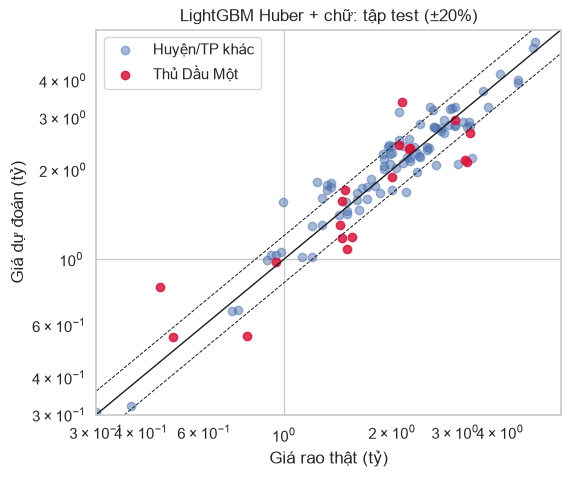

In [10]:
mo_hinh_tot = MO_HINH[ten_tot_nhat]().fit(train, train["y"])
baseline = BaselineDonGiaDuAn().fit(train, train["y"])
p_test = {ten_tot_nhat: mo_hinh_tot.predict(test), f"Phần A – {TOT_A}": mo_hinh_a.predict(test[DAC_TRUNG].astype(float)),
          "Baseline (đơn giá dự án)": baseline.predict(test)}
m_all, m_tdm = np.ones(len(test), bool), (test["tdm"] == 1).to_numpy()
bang_test, bang_test_tdm = bang_danh_gia(test, p_test, m_all), bang_danh_gia(test, p_test, m_tdm)
print("TẬP TEST – tất cả:"); display(bang_test.round(2))
print("TẬP TEST – Thủ Dầu Một:"); display(bang_test_tdm.round(2))
# Tập test nhỏ dễ "xui": kiểm tra căn test thuộc dự án có rất ít tin trong tập học (mô hình khó biết mặt bằng giá dự án đó)
so_tin_hoc = train["du_an"].value_counts()
it_tin = test["du_an"].map(so_tin_hoc).fillna(0) < 3
print(f"Căn test thuộc dự án có < 3 tin trong tập học: {int(it_tin.sum())}/{len(test)} (TDM: {int(it_tin[m_tdm].sum())}/{int(m_tdm.sum())}). "
      f"MAPE test trên các căn còn lại: {bang_danh_gia(test, {'x': p_test[ten_tot_nhat]}, ~it_tin.to_numpy()).iloc[0]['MAPE (%)']:.1f}%")
cv_, te_ = bang_cv.loc[ten_tot_nhat], bang_test.loc[ten_tot_nhat]
print(f"Kiểm định chéo: MAPE {cv_['MAPE (%)']:.1f}% (KTC {cv_['MAPE thấp (95%)']:.1f}–{cv_['MAPE cao (95%)']:.1f}) | test: {te_['MAPE (%)']:.1f}% "
      f"(KTC {te_['MAPE thấp (95%)']:.1f}–{te_['MAPE cao (95%)']:.1f}) → "
      + ("hai khoảng chồng nhau: test khớp kiểm định chéo." if te_['MAPE thấp (95%)'] <= cv_['MAPE cao (95%)'] and cv_['MAPE thấp (95%)'] <= te_['MAPE cao (95%)']
         else "hai khoảng KHÔNG chồng nhau: cần xem lại."))
a_ = bang_test.loc[f"Phần A – {TOT_A}"]
chong_ab = a_["MAPE thấp (95%)"] <= te_["MAPE cao (95%)"] and te_["MAPE thấp (95%)"] <= a_["MAPE cao (95%)"]
nx(f'''**Phần A so với Phần B trên tập test** (toàn bộ {int(te_["Số căn"])} căn): Phần A ({TOT_A}) sai {vn(a_["MAPE (%)"])}% (KTC {vn(a_["MAPE thấp (95%)"])}–{vn(a_["MAPE cao (95%)"])}%), Phần B ({ten_tot_nhat}) sai {vn(te_["MAPE (%)"])}% (KTC {vn(te_["MAPE thấp (95%)"])}–{vn(te_["MAPE cao (95%)"])}%) → {"hai khoảng chồng nhau: chưa đủ bằng chứng Phần B tốt hơn trên tập test" if chong_ab else "hai khoảng không chồng nhau: phần đơn giá dự án của Phần B cải thiện rõ so với chỉ dùng thông số căn hộ"}.''')

fig, ax = plt.subplots(figsize=(6, 5))
gt, gd = test["gia_ty"].to_numpy(), np.exp(p_test[ten_tot_nhat])
ax.scatter(gt[~m_tdm], gd[~m_tdm], alpha=0.5, label="Huyện/TP khác"); ax.scatter(gt[m_tdm], gd[m_tdm], alpha=0.85, color="crimson", label="Thủ Dầu Một")
lim = [0.3, max(gt.max(), gd.max()) * 1.1]
ax.plot(lim, lim, "k-", lw=1); ax.plot(lim, [x * 1.2 for x in lim], "k--", lw=0.7); ax.plot(lim, [x / 1.2 for x in lim], "k--", lw=0.7)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Giá rao thật (tỷ)", ylabel="Giá dự đoán (tỷ)", title=f"{ten_tot_nhat}: tập test (±20%)")
ax.legend(); plt.show()

**Mô hình có lệch theo phân khúc không?** Sai lệch có dấu của dự đoán ngoài-fold (dương = đoán cao hơn giá rao) theo phân khúc.

In [11]:
lech = pd.DataFrame({"Phân khúc": np.where(train["noxh"] == 1, "Nhà ở xã hội", "Thương mại"),
                     "lech_pt": (np.exp(OOF[ten_tot_nhat].mean(0) - train["y"].to_numpy()) - 1) * 100})
lech.groupby("Phân khúc")["lech_pt"].describe(percentiles=[.1, .5, .9])[["count", "10%", "50%", "90%"]].round(1)

,count,10%,50%,90%
Phân khúc,,,,
Nhà ở xã hội,44.0,-10.6,13.5,42.4
Thương mại,426.0,-19.3,0.4,17.0


## Bước 9: Khoảng giá 80% (hiệu chỉnh từ sai số ngoài-fold)
**Lưu ý khi đọc phần test riêng của Thủ Dầu Một:** chỉ vài chục căn, và cách chia ngẫu nhiên có thể dồn phần lớn tin của **một dự án** vào tập test (dòng in ở Bước 8). Khi đó mô hình không biết mặt bằng giá của dự án ấy, nên sai số và độ phủ trên phần test này kém hơn hẳn. Con số đại diện cho Thủ Dầu Một là **kiểm định chéo trên các căn TDM** ở Bước 7 (nhiều căn hơn, mỗi căn được kiểm tra 3 lần).

Cách làm giống notebook nhà phố: phân vị 10% và 90% của sai số ngoài-fold (log) trên tập train làm biên của khoảng, rồi kiểm tra độ phủ trên tập test bằng kiểm định nhị thức. Như notebook nhà phố đã nói rõ: đây là **khoảng hiệu chỉnh thực nghiệm** theo ý tưởng conformal, không phải bảo đảm lý thuyết; độ tin cậy của nó nằm ở độ phủ quan sát trên test.

**Biên độ riêng cho nhà ở xã hội (hiệu chỉnh theo nhóm).** Giá rao nhà ở xã hội dao động mạnh hơn hẳn căn hộ thương mại (người bán "ngộp", giá chênh nhiều giữa các căn giống nhau). Một biên độ chung sẽ quá hẹp với phân khúc này, nên tính phân vị sai số riêng cho hai nhóm và so độ phủ.

In [12]:
from scipy.stats import binomtest
nhom_kh = lambda d: np.where(d["noxh"].fillna(0).to_numpy() == 1, "noxh", "thuong_mai")
R = train["y"].to_numpy() - OOF[ten_tot_nhat]                                   # (số lần lặp × số căn)
KHOANG = hieu_chinh_khoang(R.ravel(), np.tile(nhom_kh(train), R.shape[0]), toi_thieu=60)
Q = KHOANG["chung"]
g_tr = np.tile(nhom_kh(train), R.shape[0]); q_tr = phan_vi_cho(g_tr, KHOANG); rr = R.ravel()
display(pd.DataFrame({"Số căn": [int((nhom_kh(train) == g).sum()) for g in ["thuong_mai", "noxh"]],
                      "Độ phủ – biên độ chung (%)": [np.mean(((rr >= Q["q10"]) & (rr <= Q["q90"]))[g_tr == g]) * 100 for g in ["thuong_mai", "noxh"]],
                      "Độ phủ – biên độ theo phân khúc (%)": [np.mean(((rr >= q_tr["q10"]) & (rr <= q_tr["q90"]))[g_tr == g]) * 100 for g in ["thuong_mai", "noxh"]],
                      "Biên độ 80%": [f"{(np.exp(KHOANG['nhom'].get(g, Q)['q10']) - 1) * 100:+.0f}% … {(np.exp(KHOANG['nhom'].get(g, Q)['q90']) - 1) * 100:+.0f}%" for g in ["thuong_mai", "noxh"]]},
                     index=["Thương mại", "Nhà ở xã hội"]).round(1))
yt = test["y"].to_numpy(); pt = p_test[ten_tot_nhat]
q_te = phan_vi_cho(nhom_kh(test), KHOANG)
trong = (yt >= pt + q_te["q10"]) & (yt <= pt + q_te["q90"])
for nhan, m_ in [("test tất cả", m_all), ("test Thủ Dầu Một", m_tdm)]:
    k, n = int(trong[m_].sum()), int(m_.sum())
    p_ = binomtest(k, n, 0.8, alternative="less").pvalue
    print(f"{nhan}: {k}/{n} căn trong khoảng 80% ({k / n * 100:.0f}%), p = {p_:.2f} → "
          + ("không có bằng chứng khoảng quá hẹp" if p_ >= 0.05 else "khoảng có thể quá hẹp"))
print(f"Biên độ khoảng 80% chung: {(np.exp(Q['q10']) - 1) * 100:+.0f}% … {(np.exp(Q['q90']) - 1) * 100:+.0f}%")

,Số căn,Độ phủ – biên độ chung (%),Độ phủ – biên độ theo phân khúc (%),Biên độ 80%
Thương mại,426,81.5,80.0,-15% … +22%
Nhà ở xã hội,44,65.2,78.8,-29% … +12%


test tất cả: 81/110 căn trong khoảng 80% (74%), p = 0.06 → không có bằng chứng khoảng quá hẹp
test Thủ Dầu Một: 10/19 căn trong khoảng 80% (53%), p = 0.01 → khoảng có thể quá hẹp
Biên độ khoảng 80% chung: -17% … +21%


## Bước 10: Chẩn đoán giá từng căn hộ ở Thủ Dầu Một
Giá ước lượng của mỗi căn được tính bằng mô hình **không học căn đó và các tin gần trùng với nó** (kiểm định chéo theo nhóm trên toàn bộ dữ liệu, trung bình 3 lần lặp). Rẻ / cao hơn thị trường = giá rao nằm ngoài khoảng 80%.

In [13]:
oof_all = du_doan_cheo_lap(MO_HINH[ten_tot_nhat], df, so_lan=SO_LAN, seed=7).mean(axis=0)
df["gia_uoc_luong_ty"] = np.exp(oof_all)
q_all = phan_vi_cho(nhom_kh(df), KHOANG)                                      # biên độ theo phân khúc của từng căn
df["khoang80_thap"], df["khoang80_cao"] = np.exp(oof_all + q_all["q10"]), np.exp(oof_all + q_all["q90"])
df["chenh_lech_pt"] = (df["gia_ty"] / df["gia_uoc_luong_ty"] - 1) * 100
df["chan_doan"] = np.select([df["gia_ty"] < df["khoang80_thap"], df["gia_ty"] > df["khoang80_cao"]],
                            ["Rẻ hơn thị trường", "Cao hơn thị trường"], "Hợp lý")
tdm = df[df["tdm"] == 1]
display(tdm["chan_doan"].value_counts().to_frame("Số căn hộ TDM"))
cot = ["phuong", "du_an_goc", "dt_dat", "phong_ngu", "gia_ty", "gia_uoc_luong_ty", "khoang80_thap", "khoang80_cao", "chenh_lech_pt", "chan_doan"]
print("Căn hộ ở Phú Hòa:"); display(df[df["phu_hoa"] == 1].sort_values("chenh_lech_pt")[cot].round(2))
xuat = tdm.rename(columns={"id": "ma_tin", "url": "link_tin", "gia_ty": "gia_rao_ty", "dt_dat": "dien_tich_su_dung_m2", "du_an_goc": "du_an"})
xuat.assign(gia_du_doan_ty=xuat["gia_uoc_luong_ty"].round(3),
            khoang_80_ty=xuat["khoang80_thap"].round(2).astype(str) + " - " + xuat["khoang80_cao"].round(2).astype(str),
            chenh_lech_pt=xuat["chenh_lech_pt"].round(1), mo_hinh=ten_tot_nhat)[
    ["ma_tin", "nguon", "link_tin", "phuong", "du_an", "dien_tich_su_dung_m2", "phong_ngu", "gia_rao_ty", "gia_du_doan_ty",
     "khoang_80_ty", "chenh_lech_pt", "chan_doan", "mo_hinh"]].to_csv(KET_QUA / "output_can_ho.csv", index=False, encoding="utf-8-sig")
print("Đã ghi results/output_can_ho.csv:", len(xuat), "căn hộ Thủ Dầu Một")

,Số căn hộ TDM
chan_doan,
Hợp lý,91
Rẻ hơn thị trường,13
Cao hơn thị trường,12


Căn hộ ở Phú Hòa:


,phuong,du_an_goc,dt_dat,phong_ngu,gia_ty,gia_uoc_luong_ty,khoang80_thap,khoang80_cao,chenh_lech_pt,chan_doan
277,phu hoa,Becamex Tower,55.9,2.0,1.50,1.76,1.50,2.16,-14.93,Hợp lý
275,phu hoa,Happy One Bình Dương,54.0,2.0,1.48,1.71,1.46,2.10,-13.56,Hợp lý
301,phu hoa,Happy One Bình Dương,76.0,3.0,1.90,2.14,1.82,2.62,-11.16,Hợp lý
324,phu hoa,Happy One - Central,70.0,2.0,2.35,2.63,2.23,3.21,-10.49,Hợp lý
294,phu hoa,Happy One Central,49.0,1.0,1.80,1.97,1.67,2.41,-8.64,Hợp lý
300,phu hoa,None,73.0,3.0,1.90,2.03,1.72,2.48,-6.26,Hợp lý
259,phu hoa,None,44.0,1.0,1.05,1.12,0.95,1.37,-6.03,Hợp lý
338,phu hoa,None,93.0,3.0,3.40,3.61,3.06,4.41,-5.69,Hợp lý
326,phu hoa,Happy One Central,70.0,2.0,2.45,2.56,2.17,3.13,-4.16,Hợp lý
285,phu hoa,Happy One Bình Dương,54.0,2.0,1.60,1.62,1.38,1.99,-1.48,Hợp lý


Đã ghi results/output_can_ho.csv: 116 căn hộ Thủ Dầu Một


## Bước 11: Lưu mô hình
- `models/mo_hinh_gia_can_ho.joblib`: mô hình đầy đủ + phân vị sai số.
- `models/mo_hinh_gia_can_ho.json`: **mô hình rút gọn cho trang web**. Nó gồm bảng đơn giá theo dự án (co về đơn giá phường khi dự án có ít tin) cộng với hồi quy Ridge trên 7 thông số người dùng nhập được (diện tích, phòng ngủ, WC, tầng, sổ hồng, nội thất, nhà ở xã hội). Sai số kiểm định chéo theo nhóm của chính mô hình này được ghi kèm.
- `dataset/processed/can_ho_da_xu_ly.csv`: dữ liệu sạch + giá ước lượng.

In [14]:
import json, joblib
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

mo_hinh_cuoi = MO_HINH[ten_tot_nhat]().fit(df, df["y"])
joblib.dump({"model": mo_hinh_cuoi, "ten": ten_tot_nhat, "phan_vi_sai_so": Q, "khoang_theo_phan_khuc": KHOANG, "dac_trung": DAC_TRUNG,
             "ngay_du_lieu": str(raw_ct["ngay_thu_thap"].iloc[0]), "so_can": len(df)}, MODEL_DIR / "mo_hinh_gia_can_ho.joblib")

WEB = ["log_dt", "phong_ngu", "so_wc", "tang_so", "so_hong", "noi_that_cap", "noxh"]
M_CO = 3.0       # số căn "ảo" kéo đơn giá dự án về đơn giá phường khi dự án có ít tin

class CanHoWeb(BaseEstimator, RegressorMixin):
    # log(đơn giá) = đơn giá dự án (co về phường, rồi về toàn vùng) + Ridge(7 thông số) ; giá = đơn giá × diện tích
    def fit(self, X, y):
        u = np.asarray(y) - np.log(X["dt_dat"].to_numpy())
        s = pd.DataFrame({"u": u, "da": X["du_an"].values, "ph": (X["quan"] + "|" + X["phuong"].astype(str)).values})
        self.g_ = float(np.median(u))
        ph = s.groupby("ph")["u"].agg(["sum", "count"]); self.ph_ = ((ph["sum"] + M_CO * self.g_) / (ph["count"] + M_CO)).to_dict()
        da = s.dropna(subset=["da"]).groupby("da").agg(sum=("u", "sum"), count=("u", "size"), ph=("ph", lambda x: next(iter(x.mode()), None)))   # mode rỗng khi phường thiếu
        self.da_ = {k: (r["sum"] + M_CO * self.ph_.get(r["ph"], self.g_)) / (r["count"] + M_CO) for k, r in da.iterrows()}
        nen = self._nen(X)
        self.r_ = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3.0)).fit(X[WEB].astype(float), u - nen)
        return self
    def _nen(self, X):
        ph = (X["quan"] + "|" + X["phuong"].astype(str)).map(self.ph_).fillna(self.g_)
        return X["du_an"].map(self.da_).fillna(ph).to_numpy(float)
    def predict(self, X):
        return self._nen(X) + self.r_.predict(X[WEB].astype(float)) + np.log(X["dt_dat"].to_numpy())

P_web = du_doan_cheo_lap(CanHoWeb, df, so_lan=SO_LAN)
cv_web = bang_danh_gia(df, {"Web": P_web}, np.ones(len(df), bool)).iloc[0]
print(f"Mô hình web (bảng dự án + Ridge 7 thông số) – kiểm định chéo theo nhóm: MAPE {cv_web['MAPE (%)']:.1f}% "
      f"(KTC {cv_web['MAPE thấp (95%)']:.1f}–{cv_web['MAPE cao (95%)']:.1f})")
web = CanHoWeb().fit(df, df["y"])
imp, sc, rg = web.r_.named_steps["simpleimputer"], web.r_.named_steps["standardscaler"], web.r_.named_steps["ridge"]
ten_da = df.dropna(subset=["du_an"]).groupby("du_an").agg(ten=("du_an_goc", lambda x: x.dropna().mode()[0] if x.notna().any() else None),
                                                          so_tin=("y", "size"), quan=("quan", "first"), phuong=("phuong", "first"))
du_an_web = [{"ma": k, "ten": (r["ten"] or k.title()), "so_tin": int(r["so_tin"]), "quan": r["quan"], "phuong": r["phuong"],
              "log_don_gia": round(web.da_[k], 4)} for k, r in ten_da.iterrows() if r["so_tin"] >= 2 and k in web.da_]
json.dump({"features": WEB, "medians": imp.statistics_.tolist(), "scaler": {"mean": sc.mean_.tolist(), "scale": sc.scale_.tolist()},
           "coef": rg.coef_.tolist(), "intercept": float(rg.intercept_), "du_an": sorted(du_an_web, key=lambda d: d["ten"]),
           "phuong": {k: round(v, 4) for k, v in web.ph_.items()}, "toan_vung": round(web.g_, 4),
           "cv_mape": round(float(cv_web["MAPE (%)"]), 1), "phan_vi_sai_so": KHOANG["nhom"].get("thuong_mai", Q), "phan_vi_sai_so_noxh": KHOANG["nhom"].get("noxh", Q), "mo_hinh_day_du": ten_tot_nhat,
           "mo_hinh_day_du_mape": round(float(bang_cv.loc[ten_tot_nhat, "MAPE (%)"]), 1), "so_can": len(df)},
          open(MODEL_DIR / "mo_hinh_gia_can_ho.json", "w", encoding="utf-8"), ensure_ascii=False)
ghi = lambda b: b.round(3).reset_index(names="Mô hình").to_dict("records")
json.dump({"ten_mo_hinh": ten_tot_nhat, "kiem_dinh_cheo": ghi(bang_cv), "kiem_dinh_cheo_tdm": ghi(bang_cv_tdm), "chon_mo_hinh": ghi(so_sanh.astype(float)),
           "test": ghi(bang_test), "test_tdm": ghi(bang_test_tdm), "phan_vi_sai_so_log": Q, "mo_hinh_web_mape": round(float(cv_web["MAPE (%)"]), 2),
           "so_can": {"tat_ca": len(df), "tdm": int(df["tdm"].sum()), "phu_hoa": int(df["phu_hoa"].sum()), "du_an": int(df["du_an"].nunique())}},
          open(MODEL_DIR / "danh_gia_mo_hinh_can_ho.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
df.drop(columns=["van_ban", "mo_ta"]).to_csv(PROC / "can_ho_da_xu_ly.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", sorted(p.name for p in MODEL_DIR.glob("*can_ho*")))

Mô hình web (bảng dự án + Ridge 7 thông số) – kiểm định chéo theo nhóm: MAPE 14.6% (KTC 13.1–16.1)
Đã lưu: ['danh_gia_mo_hinh_can_ho.json', 'mo_hinh_gia_can_ho.joblib', 'mo_hinh_gia_can_ho.json']


Hàm dự đoán cho một căn hộ. Thông số nào không biết thì để `None`. Nếu không nhập mô tả, hàm tự tạo một tiêu đề ngắn kiểu tin rao từ các thông số, vì mô hình chữ được học trên các tin luôn có tiêu đề.

In [15]:
goi = joblib.load(MODEL_DIR / "mo_hinh_gia_can_ho.joblib")
xy_du_an = df.groupby("du_an")[["lat", "lon", "quan", "phuong"]].first()

def du_doan_gia_can_ho(dt_su_dung, du_an=None, phong_ngu=None, so_wc=None, tang=None, so_hong=None, noi_that_cap=None,
                       nha_o_xa_hoi=0, quan="thu dau mot", phuong="phu hoa", mo_ta=""):
    ma = ten_du_an(du_an) if du_an else None
    if ma in xy_du_an.index:
        lat, lon, quan, phuong = xy_du_an.loc[ma].values
    else:
        g = df[(df["quan"] == quan) & (df["phuong"] == phuong)]
        lat, lon = (g["lat"].median(), g["lon"].median()) if len(g) else (df["lat"].median(), df["lon"].median())
    if not mo_ta.strip():
        # Mô hình chữ học trên tin rao luôn có tiêu đề; để trống sẽ làm dự đoán lệch. Khi không có mô tả,
        # tạo một tiêu đề ngắn đúng kiểu tin rao từ chính các thông số đã nhập.
        mo_ta = f"Bán căn hộ {du_an or ''} {dt_su_dung:g}m2" + (f" {phong_ngu:g}PN" if phong_ngu else "") + (f" {so_wc:g}WC" if so_wc else "")
    can = pd.DataFrame([{"dt_dat": dt_su_dung, "phong_ngu": phong_ngu, "so_wc": so_wc, "tang_so": tang, "so_hong": so_hong,
                         "noi_that_cap": noi_that_cap, "noxh": float(nha_o_xa_hoi), "loai_dac_biet": 0.0, "can_ho_dich_vu": 0.0,
                         "da_ban_giao": np.nan, "quan": quan, "phuong": phuong, "du_an": ma, "duong": ma, "lat": lat, "lon": lon,
                         "van_ban": khong_dau(mo_ta)}])
    can = pd.concat([can, trich_dac_trung_chu(can["van_ban"])], axis=1)
    for k_ in ["t_view", "t_tang_cao", "t_so_cap", "t_noxh"]:
        can[k_] = 0
    can["log_dt"] = np.log(can["dt_dat"]); can["kc_trung_tam_km"] = np.hypot((lat - 10.9805) * 110.6, (lon - 106.6520) * 109.3)
    can = can.astype({c_: float for c_ in ["phong_ngu", "so_wc", "tang_so", "so_hong", "noi_that_cap", "da_ban_giao"]})
    p = float(goi["model"].predict(can)[0])
    q = goi["khoang_theo_phan_khuc"]["nhom"].get("noxh" if nha_o_xa_hoi else "thuong_mai", goi["phan_vi_sai_so"])
    return {"gia_du_doan_ty": round(np.exp(p), 2), "khoang_80_ty": (round(np.exp(p + q["q10"]), 2), round(np.exp(p + q["q90"]), 2)),
            "don_gia_tr_m2": round(np.exp(p) * 1000 / dt_su_dung, 1)}

vi_du = {
    "Happy One Central (Phú Hòa), 2PN 2WC 68 m², sổ hồng": dict(dt_su_dung=68, du_an="Happy One Central", phong_ngu=2, so_wc=2, so_hong=1, noi_that_cap=1),
    "Căn hộ 2PN 60 m² không rõ dự án, Phú Hòa": dict(dt_su_dung=60, phong_ngu=2, so_wc=2),
    "Nhà ở xã hội Becamex Định Hòa, 2PN 50 m²": dict(dt_su_dung=50, du_an="Nhà ở xã hội Becamex Định Hòa", phong_ngu=2, so_wc=1, nha_o_xa_hoi=1),
}
pd.DataFrame({k: du_doan_gia_can_ho(**v_) for k, v_ in vi_du.items()}).T

,gia_du_doan_ty,khoang_80_ty,don_gia_tr_m2
"Happy One Central (Phú Hòa), 2PN 2WC 68 m², sổ hồng",2.55,"(2.17, 3.13)",37.6
"Căn hộ 2PN 60 m² không rõ dự án, Phú Hòa",1.7,"(1.45, 2.08)",28.3
"Nhà ở xã hội Becamex Định Hòa, 2PN 50 m²",0.86,"(0.6, 0.96)",17.1


## Kết luận
- Đề tài định giá được **cả hai dạng nhà ở**: nhà gắn liền với đất (notebook `2324801030095.ipynb`) và **căn hộ chung cư** (notebook này), trên dữ liệu tin rao thật, cùng một quy trình đánh giá khắt khe (kiểm định chéo lặp chia theo nhóm, khoảng tin cậy 95%, tập test giữ riêng).
- Với căn hộ, **dự án** là yếu tố quyết định giá. Mô hình học máy cải thiện thêm so với cách "đơn giá dự án × diện tích" nhờ số phòng, tầng, pháp lý, nội thất và mô tả tin (mức cải thiện và khoảng tin cậy ở Bước 7).
- **Phần A** (Bước 6b) cho thấy giới hạn của các mô hình trong môn học khi chỉ dùng thông số của căn: thiếu thông tin dự án. Phần B đưa đơn giá dự án (tính trên tập học) vào làm đặc trưng; so sánh hai phần trên tập test ở Bước 8.
- Mỗi căn hộ Thủ Dầu Một có **chẩn đoán** rẻ / hợp lý / cao so với thị trường (`results/output_can_ho.csv`).

**Hạn chế**
- Thủ Dầu Một và đặc biệt **Phú Hòa có ít tin căn hộ**; mô hình dựa nhiều vào dữ liệu Dĩ An, Thuận An. Kết quả riêng cho Phú Hòa chỉ mang tính tham khảo.
- Dự án có ít tin thì đơn giá dự án kém chắc chắn (mô hình kéo về đơn giá phường). Tin không ghi tên dự án chỉ được định giá theo vị trí.
- Tin bán mới của chủ đầu tư (giá sơ cấp, nhiều ưu đãi thanh toán) và tin bán lại (thứ cấp) lẫn trong dữ liệu; mô hình nhận biết một phần qua từ khóa `t_so_cap`.
- **Nhà ở xã hội** chỉ có vài chục tin: mô hình vẫn có xu hướng đoán cao hơn giá rao (độ lệch trung vị ở bảng phân khúc, Bước 8), dù đã co đơn giá theo phân khúc. Với căn nhà ở xã hội nên đọc kèm khoảng giá thay vì một con số.
- Vẫn là **giá rao**, chưa phải giá giao dịch.